In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense
from tensorflow.keras.callbacks import EarlyStopping



In [2]:
# 1. Create sample time-series data
np.random.seed(42)

t = np.arange(1000)
data = np.sin(0.02 * t) + 0.3 * np.sin(0.05 * t)
data += np.random.normal(0, 0.05, len(t))

data = data.reshape(-1, 1)

# 2. Train-test split (chronological)
split = int(len(data) * 0.8)

train_data = data[:split]
test_data = data[split:]

# 3. Scale using training data only
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)

# Include previous training values for test windows
test_input = np.concatenate(
    [train_data[-30:], test_data], axis=0
)
test_scaled = scaler.transform(test_input)




In [3]:
# 4. Create sequences
def create_sequences(dataset, window_size=30):
    X, y = [], []

    for i in range(window_size, len(dataset)):
        X.append(dataset[i-window_size:i, 0])
        y.append(dataset[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled)
X_test, y_test = create_sequences(test_scaled)

# GRU expects: (samples, timesteps, features)
X_train = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)
X_test = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)



X_train shape: (770, 30, 1)
X_test shape: (200, 30, 1)


In [4]:
# 5. Build GRU model
model = Sequential([
    GRU(32, input_shape=(30, 1)),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 6. Train model
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)



Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step - loss: 0.1116 - val_loss: 0.0253
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0186 - val_loss: 0.0022
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0098 - val_loss: 0.0073
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0077 - val_loss: 0.0030
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0048 - val_loss: 0.0021
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0029 - val_loss: 0.0013
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0018 - val_loss: 8.9228e-04
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0012 - val_loss: 7.2167e-04
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 9.7154e-04 - val_loss: 6.6581e-04
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 9.0111e-04 - val_loss: 6.4587e-04
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 8.7751e-04 - val_loss: 6.3566e-04
Epoch 12/30
20/20 ━━━━━━━━━━━━━

In [6]:
# 7. Predict test data
pred_scaled = model.predict(X_test, verbose=0)

predictions = scaler.inverse_transform(pred_scaled)
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# 8. Evaluate
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))



MAE: 0.0564
RMSE: 0.0691


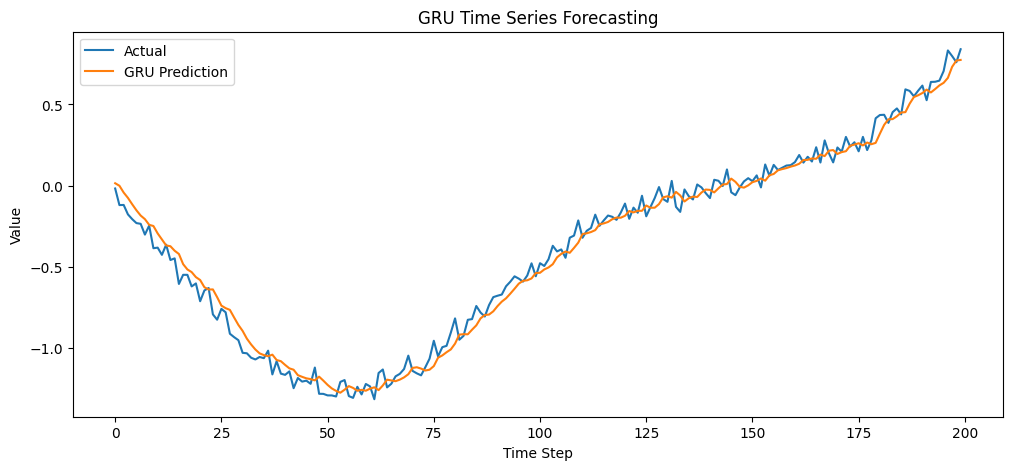

In [7]:
# 9. Plot actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual")
plt.plot(predictions, label="GRU Prediction")
plt.title("GRU Time Series Forecasting")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.legend()
plt.show()



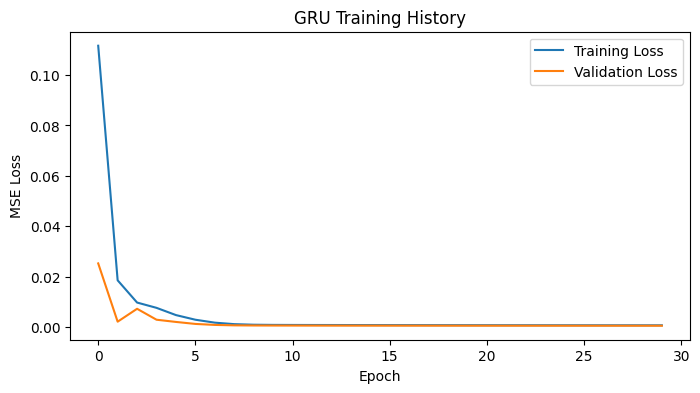

In [8]:
# 10. Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("GRU Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()